In [1]:
import pandas as pd

url = 'https://raw.githubusercontent.com/shrfr/nafld-fibrosis-prediction/main/data/NAFLD_clean.xlsx'
data = pd.read_excel(url, sheet_name='Full_Data')
mr   = pd.read_excel(url, sheet_name='Model_Ready')
print(data.shape, mr.shape)    # (605, 67) (605, 41)

(605, 67) (605, 41)


In [2]:
import numpy as np, warnings
warnings.filterwarnings('ignore')
import matplotlib.pyplot as plt
from sklearn.model_selection import (train_test_split, RepeatedStratifiedKFold, StratifiedKFold,
                                     cross_validate, cross_val_predict, GridSearchCV)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix, classification_report
from sklearn.base import clone

SEED = 42
drop  = ['Patient No.','SigFibrosis','AdvFibrosis','AtRiskNASH_calc','FibGroup','FIB4','Height','Weight']
feats = [c for c in mr.columns if c not in drop]
smoke = 'Smoking Status (Never Smoked=1, Left Smoking=2, Smoking=3)'
bin_cols  = [c for c in feats if c != smoke and data[c].nunique() <= 2]
num_feats = [c for c in feats if c not in bin_cols + [smoke]]

assert len(feats) == 33 and len(num_feats) == 27 and len(bin_cols) == 5
assert not (set(feats) & (set(drop) | {'n_panel','in_panel','Fibrosis','NAS'})), 'leakage column in feats'

In [3]:
X = data[feats]; y = data['SigFibrosis']
strata = y.astype(str) + '_' + data['in_panel'].astype(str)
X_train, X_test, y_train, y_test, s_train, s_test = train_test_split(
    X, y, strata, test_size=0.2, stratify=strata, random_state=SEED)
print(X_train.shape, X_test.shape, y_train.mean().round(3), y_test.mean().round(3))

(484, 33) (121, 33) 0.362 0.364


In [4]:
pre = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), num_feats),
    ('bin', SimpleImputer(strategy='most_frequent'), bin_cols),
    ('smk', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                      ('oh', OneHotEncoder(handle_unknown='ignore'))]), [smoke]),
], sparse_threshold=0)

lr = Pipeline([('pre', pre), ('model', LogisticRegression(max_iter=3000, class_weight='balanced'))])

In [5]:
splits = list(RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED).split(X_train, s_train))
scoring = ['roc_auc', 'average_precision', 'recall', 'precision', 'f1']
r = cross_validate(lr, X_train, y_train, cv=splits, scoring=scoring, n_jobs=-1, return_train_score=True)
for s in scoring:
    print(s, '%.3f +/- %.3f' % (r['test_'+s].mean(), r['test_'+s].std()))
print('train AUC %.3f' % r['train_roc_auc'].mean())

roc_auc 0.737 +/- 0.043
average_precision 0.620 +/- 0.052
recall 0.657 +/- 0.059
precision 0.553 +/- 0.053
f1 0.599 +/- 0.050
train AUC 0.817


In [6]:
gs = GridSearchCV(lr, {'model__C': [0.001, 0.01, 0.03, 0.1, 0.3, 1, 3, 10]},
                  scoring='roc_auc', cv=splits, n_jobs=-1)
gs.fit(X_train, y_train)
print(pd.DataFrame(gs.cv_results_)[['param_model__C','mean_test_score','std_test_score']].round(3))
print(gs.best_params_, round(gs.best_score_, 3))
best = gs.best_estimator_.fit(X_train, y_train)

   param_model__C  mean_test_score  std_test_score
0           0.001            0.725           0.046
1           0.010            0.740           0.043
2           0.030            0.744           0.043
3           0.100            0.743           0.041
4           0.300            0.740           0.042
5           1.000            0.737           0.043
6           3.000            0.736           0.044
7          10.000            0.735           0.044
{'model__C': 0.03} 0.744


,feature,coef,odds_ratio
0,num__Age,0.399,1.490
28,"bin__Diyabetes Mellitus (No=0, Yes=1)",0.358,1.430
9,num__GGT,0.238,1.269
3,num__Hip Circumference,0.231,1.260
14,num__Albumin,0.227,1.255
26,num__Hemoglobin - A1C,0.223,1.250
30,"bin__Hyperlipidemia (No=0, Yes=1)",0.190,1.210
1,num__Body Mass Index,0.182,1.200
33,"smk__Smoking Status (Never Smoked=1, Left Smok...",-0.170,0.844
6,num__AST,0.144,1.155


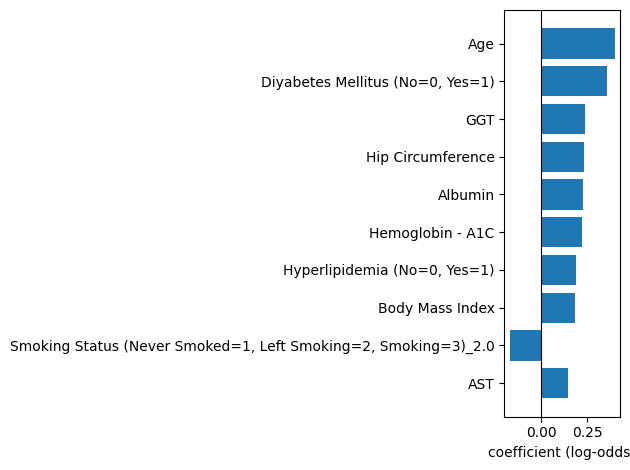

In [7]:
names = best.named_steps['pre'].get_feature_names_out()
coef  = best.named_steps['model'].coef_[0]
coefs = (pd.DataFrame({'feature': names, 'coef': coef, 'odds_ratio': np.exp(coef)})
           .assign(abs=lambda d: d.coef.abs()).sort_values('abs', ascending=False).drop(columns='abs'))
display(coefs.head(10).round(3))

top = coefs.head(10).iloc[::-1]
plt.barh(top['feature'].str.replace(r'^(num|bin|smk)__', '', regex=True), top['coef'])
plt.axvline(0, color='k', lw=0.8); plt.xlabel('coefficient (log-odds)'); plt.tight_layout(); plt.show()

In [8]:
skf = list(StratifiedKFold(5, shuffle=True, random_state=SEED).split(X_train, s_train))
p_oof = cross_val_predict(clone(best), X_train, y_train, cv=skf, method='predict_proba')[:, 1]
yt = y_train.values
fpr, tpr, thr = roc_curve(yt, p_oof)
i = np.argmax(tpr >= 0.80)
THRESH = float(thr[i])
print('threshold', round(THRESH, 3), '| sensitivity', round(tpr[i], 2), '| specificity', round(1 - fpr[i], 2))

threshold 0.428 | sensitivity 0.8 | specificity 0.61


In [9]:
p_test = best.predict_proba(X_test)[:, 1]; yte = y_test.values
f4 = data.loc[X_test.index, 'FIB4'].values; ok = ~np.isnan(f4)
print('Test AUC  model:', round(roc_auc_score(yte, p_test), 3),
      '| FIB-4:', round(roc_auc_score(yte[ok], f4[ok]), 3))
pred = p_test >= THRESH
print(confusion_matrix(yte, pred))
print(classification_report(yte, pred, digits=2))
f4pred = f4[ok] >= 1.3
print('FIB-4 @1.3  sens', round(f4pred[yte[ok]==1].mean(), 2), 'spec', round((~f4pred)[yte[ok]==0].mean(), 2))

Test AUC  model: 0.691 | FIB-4: 0.755
[[50 27]
 [16 28]]
              precision    recall  f1-score   support

           0       0.76      0.65      0.70        77
           1       0.51      0.64      0.57        44

    accuracy                           0.64       121
   macro avg       0.63      0.64      0.63       121
weighted avg       0.67      0.64      0.65       121

FIB-4 @1.3  sens 0.48 spec 0.83


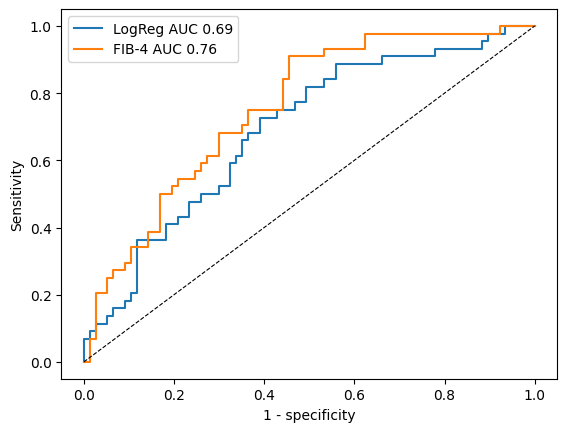

['logreg_model.joblib']

In [10]:
fpr_t, tpr_t, _ = roc_curve(yte, p_test)
plt.plot(fpr_t, tpr_t, label='LogReg AUC %.2f' % roc_auc_score(yte, p_test))
fp, tp, _ = roc_curve(yte[ok], f4[ok])
plt.plot(fp, tp, label='FIB-4 AUC %.2f' % roc_auc_score(yte[ok], f4[ok]))
plt.plot([0, 1], [0, 1], 'k--', lw=0.8)
plt.xlabel('1 - specificity'); plt.ylabel('Sensitivity'); plt.legend(); plt.show()

import joblib
joblib.dump({'model': best, 'threshold': THRESH, 'features': feats}, 'logreg_model.joblib')

## Logistic Regression: Summary Notes

**Objective:** Predict significant fibrosis (F2 or higher, `SigFibrosis`) in NAFLD patients from 33 routine clinical and lab features, and use logistic regression as the interpretable baseline model.

**Data and setup**
- 605 patients. Split 80/20 into 484 train and 121 test, stratified on the target and `in_panel`. About 36% are positive in both sets.
- 33 features were used. Biopsy columns, FIB-4, IDs, `n_panel` and `in_panel` were excluded to prevent leakage. Height and Weight were dropped because BMI covers them.
- Preprocessing sits inside the pipeline and is fitted on training folds only. Numeric features use median imputation and standard scaling, binary features use most-frequent imputation, and smoking status is one-hot encoded.
- Class imbalance was handled with `class_weight='balanced'`, with no SMOTE.

**Results**

| Item | Value |
|---|---|
| CV ROC-AUC, default C=1 (5x5 repeated CV) | 0.737 ± 0.043 |
| CV PR-AUC | 0.620 ± 0.052 |
| Train ROC-AUC | 0.817 |
| Tuned C | 0.03 (CV AUC 0.744) |
| Threshold (80% sensitivity on out-of-fold training predictions) | 0.43 |
| Test ROC-AUC | 0.691 |
| Test sensitivity / specificity at the threshold | 0.64 / 0.65 |
| FIB-4 test AUC | 0.755 |
| FIB-4 at cutoff 1.3 on the test set | sensitivity 0.48, specificity 0.83 |

**Interpretation**
- The strongest predictors were age (OR 1.49), diabetes (1.43), GGT (1.27), HbA1c (1.25), hyperlipidemia (1.21), BMI (1.20) and AST (1.16). This agrees with the EDA and with clinical knowledge.
- Odds ratios for numeric features are per +1 standard deviation.
- Some coefficients (e.g. albumin, hip circumference) point against expectation. Correlated features share credit in a linear model, so they are not interpreted causally.
- Tuning C gave only a small gain (0.737 to 0.744), well inside the CV standard deviation.
- The model finds more fibrosis cases than FIB-4 at 1.3 (sensitivity 0.64 vs 0.48) at lower specificity.

**Limitations**
- The test set has only 121 patients (44 positives), so the intervals are wide. The test AUC of 0.69 vs FIB-4's 0.755 is best read as "comparable or slightly behind", not as a proven difference.
- Single dataset, one centre, and no external validation.
- Selective testing (the extended lab panel was ordered for sicker patients). The 15 sparse lab columns were excluded to avoid learning referral behaviour.
- Biopsy is the reference standard, and it has its own sampling error.
- This is a research model, not a diagnostic tool.

**Role in the project**
Logistic regression is the baseline. Random forest and XGBoost are compared against it, and all three are compared against FIB-4 on identical patients.

**Saved artifacts:** `logreg_model.joblib` (fitted on the training set only), the decision threshold and the feature list.